# Tests and Plots

## Imports and functions

In [3]:
from random import randint,random

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import multivariate_normal
import emcee

from benchmark_distr import sample_funnel, log_neal_funnel, log_gaussian
from HamiltonianSampler import leapfrog_d,alpha_d, gaussian_ND

In [4]:
rng = np.random.default_rng(42)

In [5]:
sigma = 130
means = [60,30]
Sigma = np.array([[sigma,0],
         [0,sigma]])
ts = np.linspace(0,100,100)

def dchain(x_0,N,dt,L,mass_matrix,method = "gaussian"):
    if method == "gaussian":
        print("Gaussian sampling")
        logp = lambda x: np.log(gaussian_ND(x,means,Sigma))
    elif method == "neal":
        print("Neal's funnel sampling")
        logp = log_neal_funnel
        is_log = True
    else:
        print("invalid method")
        return "err"
    #needs x_0 in shape (N_chains,d)
    X = np.zeros((N,len(x_0),len(x_0[0])))
    X[0] = x_0
    print(x_0.shape)
    for n in range(N-1):
        p_0 = np.squeeze(np.random.default_rng().multivariate_normal([0,0], mass_matrix, size=len(x_0)))
        #print("p:",p_0)
        x_Ldt,p_Ldt = leapfrog_d(X[n],p_0,dt,L,mass_matrix,logp)
        al = alpha_d(X[n], x_Ldt, p_0, p_Ldt, mass_matrix,logp)
        accept = rng.random(len(al)) < al                # (20,) booleans
        X[n+1] = np.where(accept[:, None], x_Ldt, X[n])
        #print("Xn:",X[n],n)

    return X


## Gaussian:

the inverse mass matrix is: [[0.0001 0.    ]
 [0.     0.0001]]
Gaussian sampling
(10, 2)


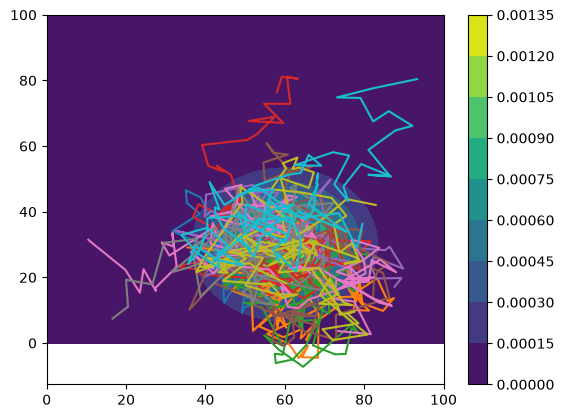

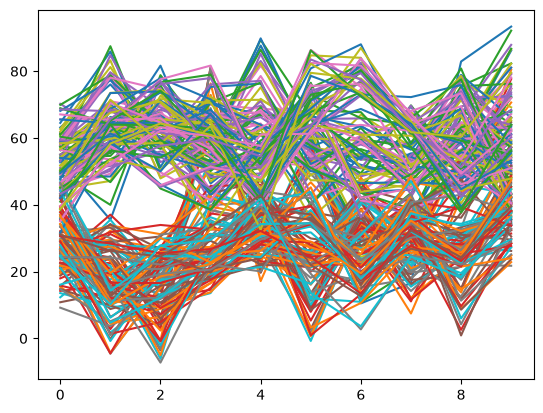

63.56316114339309 23.0173106709188


In [2]:
mean = 80
sigma = 130
means = [randint(20,100),randint(20,100)]
means = [60,30]



Sigma = np.array([[sigma,0],
         [0,sigma]])

L = 1000 #leapfrog steps
dt = 0.5 #step size
M = np.array([[10000.0,0],
              [0,10000.0]])
print("the inverse mass matrix is:",np.linalg.inv(M))

p_start = np.random.normal(0,1)
p_start = np.random.default_rng().multivariate_normal([0,0], M, size=1)

#now computes alll chains at once
X0s = [[random()*100,random()*100] for i in range(10)]
Xns = np.array(dchain(np.array(X0s),100,dt,L,M,method="gaussian"))
for i in range(10):
    plt.plot(Xns[:,i,0],Xns[:,i,1])


#Grid
x = np.linspace(0,100,100)
y = np.linspace(0,100,100)
X,Y = np.meshgrid(x,y)
pos = np.dstack((X,Y))

Z = multivariate_normal(means,Sigma).pdf(pos)




cf = plt.contourf(X,Y,Z,levels=10,cmap="viridis")
#plt.contour(X,Y,Z,levels=8,colors="white",linewidths = 0.5)
plt.colorbar(cf)
plt.show()

for Xn in Xns:
    plt.plot(Xn[:,0])
    plt.plot(Xn[:,1])
plt.show()
print(np.mean(Xn[:,0]),np.mean(Xn[:,1]))

100%|██████████| 100/100 [00:00<00:00, 3550.82it/s]

chain shape: (100, 10, 2)


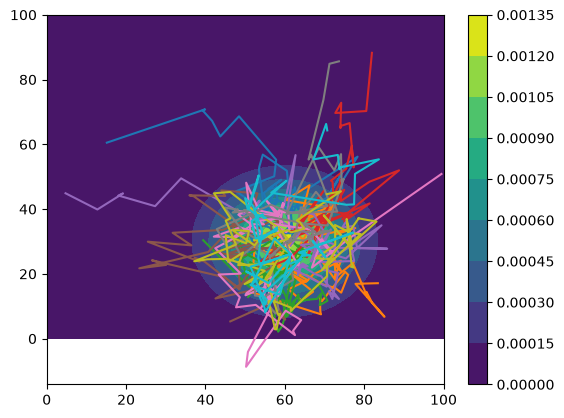

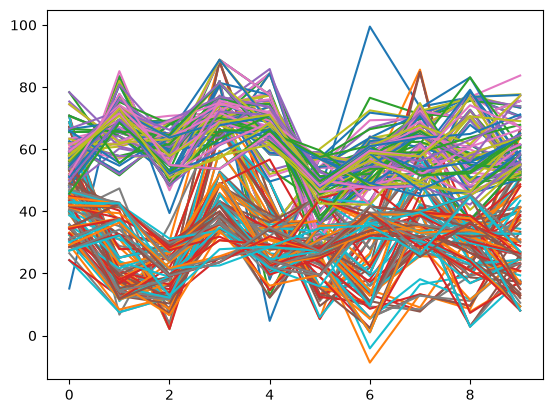

60.254128808025584 29.680371152215134


In [9]:
nsteps, nwalkers, ndim = 100, 10, 2
#burnin = nsteps // 5

X0s = [[random()*100,random()*100] for i in range(10)]
sampler = emcee.EnsembleSampler(nwalkers,ndim,log_gaussian,args=(means,Sigma))

sampler.run_mcmc(X0s,nsteps,progress=True)
Xns = sampler.get_chain()
print("chain shape:",Xns.shape)

for i in range(nwalkers):
    plt.plot(Xns[:,i,0],Xns[:,i,1])


#Grid
x = np.linspace(0,100,100)
y = np.linspace(0,100,100)
X,Y = np.meshgrid(x,y)
pos = np.dstack((X,Y))

Z = multivariate_normal(means,Sigma).pdf(pos)




cf = plt.contourf(X,Y,Z,levels=10,cmap="viridis")
#plt.contour(X,Y,Z,levels=8,colors="white",linewidths = 0.5)
plt.colorbar(cf)
plt.show()


for Xn in Xns:
    plt.plot(Xn[:,0])
    plt.plot(Xn[:,1])
plt.show()
print(np.mean(Xn[:,0]),np.mean(Xn[:,1]))


## Neal's Funnel:

Neal's funnel sampling
(10, 2)
chain shape: (100, 10, 2)


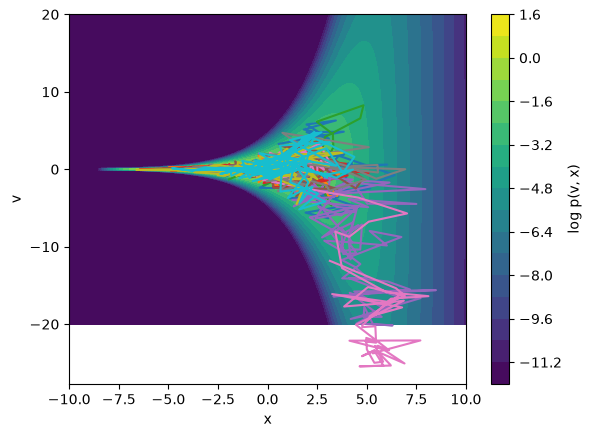

In [ ]:
nsteps, nwalkers, ndim = 100, 10, 2
#burnin = nsteps // 5

X0s = rng.normal(size=(nwalkers,ndim))
sampler = emcee.EnsembleSampler(nwalkers,ndim,log_neal_funnel)

sampler.run_mcmc(X0s,nsteps,progress=True)
Xns = sampler.get_chain()
print("chain shape:",Xns.shape)

for i in range(nwalkers):
    plt.plot(Xns[:,i,0],Xns[:,i,1])

#plot neals funnel
x = np.linspace(-20, 20, 300)
v = np.linspace(-10, 10, 300)
X, V = np.meshgrid(x, v)          
pos = np.dstack((V, X))            

logp = log_neal_funnel(pos)        

cf = plt.contourf(V,X, np.maximum(logp, -12), levels=20, cmap="viridis")
plt.colorbar(cf, label="log p(v, x)")
plt.xlabel("x")
plt.ylabel("v")
plt.show()

100%|██████████| 100/100 [00:00<00:00, 5030.77it/s]

chain shape: (100, 10, 2)


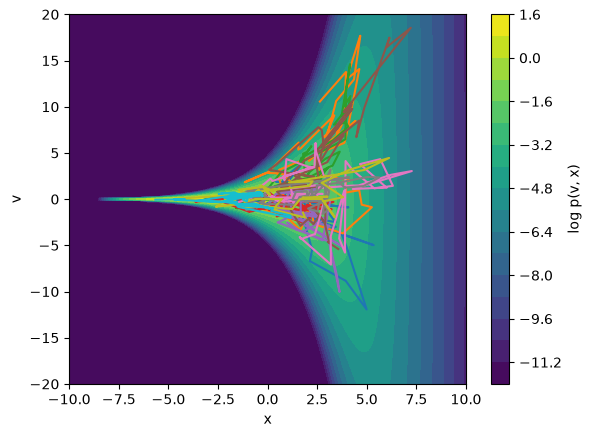

In [5]:
nsteps, nwalkers, ndim = 100, 10, 2
#burnin = nsteps // 5

X0s = rng.normal(size=(nwalkers,ndim))
sampler = emcee.EnsembleSampler(nwalkers,ndim,log_neal_funnel)

sampler.run_mcmc(X0s,nsteps,progress=True)
Xns = sampler.get_chain()
print("chain shape:",Xns.shape)

for i in range(nwalkers):
    plt.plot(Xns[:,i,0],Xns[:,i,1])

#plot neals funnel
x = np.linspace(-20, 20, 300)
v = np.linspace(-10, 10, 300)
X, V = np.meshgrid(x, v)          
pos = np.dstack((V, X))            

logp = log_neal_funnel(pos)        

cf = plt.contourf(V,X, np.maximum(logp, -12), levels=20, cmap="viridis")
plt.colorbar(cf, label="log p(v, x)")
plt.xlabel("x")
plt.ylabel("v")
plt.show()


## Marginal distributions comparison:

In [13]:
# Gaussian parameters
d = 100
rho = 0 # change for correlation
mu = 0
means = np.zeros(d)
Sigma = np.zeros((d,d))
for i in range(d):
    for j in range(d):
        means[i] = mu
        Sigma[i,j] = rho ** (np.abs(i-j))

print(Sigma)
ts = np.linspace(0,100,100)

def dchain(x_0,N,dt,L,mass_matrix,method = "gaussian"):
    if method == "gaussian":
        print("Gaussian sampling")
        logp = lambda x: np.log(gaussian_ND(x,means,Sigma))
    elif method == "neal":
        print("Neal's funnel sampling")
        logp = log_neal_funnel
        is_log = True
    else:
        print("invalid method")
        return "err"
    #needs x_0 in shape (N_chains,d)
    X = np.zeros((N,len(x_0),len(x_0[0])))
    X[0] = x_0
    print(x_0.shape)
    for n in range(N-1):
        p_0 = np.squeeze(np.random.default_rng().multivariate_normal([0,0], mass_matrix, size=len(x_0)))
        #print("p:",p_0)
        x_Ldt,p_Ldt = leapfrog_d(X[n],p_0,dt,L,mass_matrix,logp)
        al = alpha_d(X[n], x_Ldt, p_0, p_Ldt, mass_matrix,logp)
        accept = rng.random(len(al)) < al                # (20,) booleans
        X[n+1] = np.where(accept[:, None], x_Ldt, X[n])
        #print("Xn:",X[n],n)

    return X

[[1. 0. 0. ... 0. 0. 0.]
 [0. 1. 0. ... 0. 0. 0.]
 [0. 0. 1. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 1. 0. 0.]
 [0. 0. 0. ... 0. 1. 0.]
 [0. 0. 0. ... 0. 0. 1.]]


In [ ]:
L = 1000 #leapfrog steps
dt = 0.5 #step size
M = np.array([[10000.0,0],
              [0,10000.0]])
print("the inverse mass matrix is:",np.linalg.inv(M))

p_start = np.random.normal(0,1)
p_start = np.random.default_rng().multivariate_normal([0,0], M, size=1)

#now computes alll chains at once
X0s = multivariate_normal.rvs(means,Sigma,d)
Xns = np.array(dchain(np.array(X0s),100,dt,L,M,method="gaussian"))
for i in range(10):
    plt.plot(Xns[:,i,0],Xns[:,i,1])


#Grid
x = np.linspace(0,100,100)
y = np.linspace(0,100,100)
X,Y = np.meshgrid(x,y)
pos = np.dstack((X,Y))

Z = multivariate_normal(means,Sigma).pdf(pos)

cf = plt.contourf(X,Y,Z,levels=10,cmap="viridis")
#plt.contour(X,Y,Z,levels=8,colors="white",linewidths = 0.5)
plt.colorbar(cf)
plt.show()

for Xn in Xns:
    plt.plot(Xn[:,0])
    plt.plot(Xn[:,1])
plt.show()
print(np.mean(Xn[:,0]),np.mean(Xn[:,1]))

the inverse mass matrix is: [[0.0001 0.    ]
 [0.     0.0001]]
Gaussian sampling
(10, 2)


ValueError: operands could not be broadcast together with shapes (10,2) (100,) 

(1000, 2)


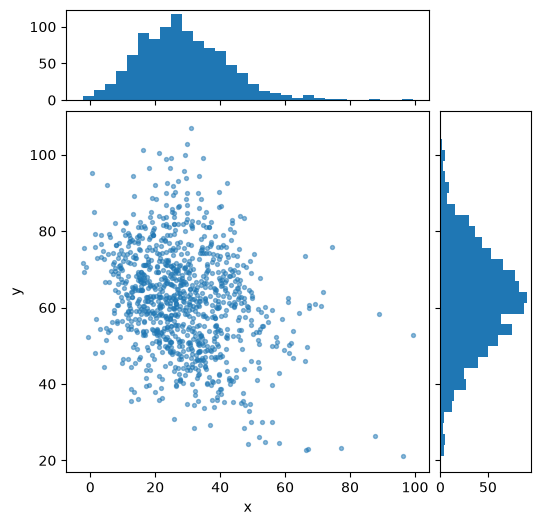

In [9]:
Xns_flat = Xns.reshape(-1, Xns.shape[-1])

print(Xns_flat.shape)

x = Xns_flat[:,0]
y = Xns_flat[:,1]

fig = plt.figure(figsize=(6, 6))
gs = fig.add_gridspec(2, 2, width_ratios=(4, 1), height_ratios=(1, 4),
                      hspace=0.05, wspace=0.05)

ax = fig.add_subplot(gs[1, 0])
ax_top = fig.add_subplot(gs[0, 0], sharex=ax)
ax_right = fig.add_subplot(gs[1, 1], sharey=ax)

ax.scatter(x, y, s=8, alpha=0.5)
ax_top.hist(x, bins=30)
ax_right.hist(y, bins=30, orientation="horizontal")

ax_top.tick_params(labelbottom=False)
ax_right.tick_params(labelleft=False)
ax.set_xlabel("x")
ax.set_ylabel("y")
plt.show()